# MLP_JK_07 — Count normalization: is the slide-level error just sequencing depth?

**Why this notebook:** in MLP_JK_06, about 60% of the test MSE was each slide's **overall level** being off, and the images could not predict it. The median number of reads per spot ranges from about 935 to 8,506 across sections, so the level may simply be **sequencing depth**. Here we test whether normalizing each spot's counts by its total (library-size normalization) removes that slide-level error.

**Two targets**
- **RAW**: `log1p(count)`, the target used so far (the stored expression files).
- **NORM**: `log1p(count / total counts of that spot × 10,000)`. The constant 10,000 is fixed, so nothing is learned from the data (in particular nothing from test spots).

**Two gene sets** (chosen per fold on training patients only, top 50 by variance)
- **G_raw**: chosen on RAW, as before.
- **G_norm**: chosen on NORM.

**Three runs per fold**

| Run | Target | Genes | What it tells us |
|---|---|---|---|
| 1 | RAW | G_raw | the current setup; must reproduce MLP_JK_03 |
| 2 | NORM | G_raw | same genes, new target: the pure effect of normalization |
| 3 | NORM | G_norm | what we would actually use from now on |

In each run: the **mean predictor**, **ridge** (as Notebook 5's "ridge raw"), **MLP D** (center + 3×3 average) and **MLP E** (center + 5×5 average), all with the same settings as MLP_JK_03, plus the **ORACLE** from MLP_JK_06 (D with each test slide's true mean; uses test labels, not a model).

**Comparing across targets:** RAW and NORM values are on different scales, so raw MSE values are **not** compared between runs. Each model is compared with its **own run's mean predictor**: NRMSE, MSE ratio (model MSE ÷ mean predictor MSE), pooled and within-patient PCC, and the **level share** (slide-level error ÷ MSE).

**Decision rule (from the proposal, set before running):** adopt NORM for later experiments if, for the best-validation model, it **lowers the level share** (a real drop: at least 3 of 4 folds and bigger than the seed spread) **without lowering validation PCC** by more than 0.005.

**Best model:** `best_check.csv` reports the usual rule, but this notebook does **not** change MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), Notebook 5's scores, `~/JHU/BDD/MLP_JK/results/` (MLP_JK_03, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_07/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check).
- `CHECK_DIR`: MLP_JK_03's saved scores. Run 1's D and E must reproduce them.
- `BEST_DIR`: the current MLP_JK_Best's saved scores, for the best check (report only).
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and `N_INNER_FOLDS`, `ALPHAS` (the ridge settings).

**Targets:** `TARGET_SUM = 10,000`, the fixed total each spot is scaled to for NORM.

**Inputs:** `NEIGHBOR_DISTANCE` (1.8 spacings = 3×3, 3.0 = 5×5), `N_PCS = 256`.

**MLP** (fixed, the same as MLP_JK_03–06): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS` (`k` values), `N_VAL_GROUPS`, `N_FINAL_SEEDS`.

**Checks and decision:** how far run 1 may be from Notebook 5 and MLP_JK_03 before the notebook stops; `VAL_PCC_TOLERANCE`, how much validation PCC NORM may lose in the decision rule.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
CHECK_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_03")
BEST_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_07"
LOG_RESULTS = True
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

TARGET_SUM = 10_000

NEIGHBOR_DISTANCE = {"3x3": 1.8, "5x5": 3.0}
N_PCS = 256

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

RIDGE_TOLERANCE = 0.001
CHECK_PCC_TOLERANCE = 0.01
CHECK_MSE_TOLERANCE = 0.005
VAL_PCC_TOLERANCE = 0.005

Names of the runs and models, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

"ridge raw" is Notebook 5's name: *raw* means ridge on the raw embeddings (through PCA 256), not the RAW target. Its target is the run's target, like every other model.

In [3]:
RUNS = {
    "raw_Graw": {"target": "raw", "gene_set": "G_raw", "label": "RAW, G_raw"},
    "norm_Graw": {"target": "norm", "gene_set": "G_raw", "label": "NORM, G_raw"},
    "norm_Gnorm": {"target": "norm", "gene_set": "G_norm", "label": "NORM, G_norm"},
}
MODEL_NAMES = {
    "mean": "mean predictor",
    "ridge": "ridge raw",
    "D": "D 3x3 average",
    "E": "E 5x5 average",
    "O": "O ORACLE (uses test labels)",
}
MLP_SETUPS = {"D": "mean_3x3", "E": "mean_5x5"}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Counts, totals, and the two targets

- **Counts:** the stored values are `log1p(count)` in float32, so `count = round(expm1(stored))`. The printout shows how far `expm1(stored)` is from a whole number (it should be tiny, from float32 rounding).
- **Total per spot:** the sum of the counts over **all 11,787 genes in `genes.txt`** (the genes in the expression files). The raw h5ad files have 18,126 genes; the extra ones are not in our data and are not counted.
- **RAW** = the stored values, unchanged (so run 1 is exactly the old setup). The printout checks that `log1p(recovered counts)` matches them.
- **NORM** = `log1p(count / total × 10,000)`. Only the spot's own counts and the fixed constant are used.
- **Spots with total = 0:** all their counts are 0, so NORM is set to 0 for every gene (the same as `log1p(0)`, and the same as RAW). They are kept so the folds and spot counts stay identical to earlier notebooks.

Each section's spots, sizes and patients are also set up here (`section_number[spot]`, `section_patient`).

In [5]:
Y_rows = Y.tocsr()
counts = Y_rows.copy().astype(np.float64)
unrounded = np.expm1(counts.data)
counts.data = np.round(unrounded)
print(f"Largest distance of expm1(stored) from a whole number: {np.abs(unrounded - counts.data).max():.6f}")
print(f"Largest difference between log1p(recovered counts) and the stored values: "
      f"{np.abs(np.log1p(counts.data) - Y_rows.data).max():.2e}")
del unrounded, Y_rows

total_counts = np.asarray(counts.sum(axis=1)).ravel()
zero_total = total_counts == 0

scale = np.zeros(len(total_counts))
scale[~zero_total] = TARGET_SUM / total_counts[~zero_total]
Y_norm = scipy.sparse.diags(scale) @ counts
Y_norm.data = np.log1p(Y_norm.data)
Y_norm = Y_norm.astype(np.float32).tocsc()
del counts

Y_targets = {"raw": Y, "norm": Y_norm}

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)
section_patient = np.array([patient_array[section_array == s][0] for s in section_ids])
section_size = np.bincount(section_number)

print(f"\nTotal counts per spot (over {len(all_genes)} genes): median {np.median(total_counts):.0f}, "
      f"min {total_counts.min():.0f}, max {total_counts.max():.0f}")
print(f"Spots with total = 0: {zero_total.sum()} of {len(total_counts)}")
for i in np.where(zero_total)[0]:
    print(f"  {section_array[i]}, row {spots.loc[i, 'row_in_sample']}, barcode {spots.loc[i, 'barcode']}: "
          f"NORM set to 0 for every gene (RAW is also 0)")
print(f"NORM: each spot's expm1 values add up to {TARGET_SUM:,} (checked on the first 5 spots: "
      f"{np.round(np.asarray(np.expm1(Y_norm[:5].toarray()).sum(axis=1)).ravel(), 1)})")

Largest distance of expm1(stored) from a whole number: 0.000261


Largest difference between log1p(recovered counts) and the stored values: 2.38e-07



Total counts per spot (over 11787 genes): median 3293, min 0, max 30784
Spots with total = 0: 1 of 30600
  SPA64, row 179, barcode 018x018: NORM set to 0 for every gene (RAW is also 0)
NORM: each spot's expm1 values add up to 10,000 (checked on the first 5 spots: [ 9999.9 10000.2 10000.  10000.1 10000. ])


## Step 3. Neighborhoods (same definition as Notebook 5 and MLP_JK_03)

For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (3×3) or 3.0 spacings (5×5), **including the spot itself**. Edge spots are averaged over what exists.

In [6]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%


5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


## Step 4. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. The same 4 folds as every earlier notebook.

In [7]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 5. Gene choice, scoring, and the error split

**`choose_genes(Y_target, train_index)`**: the 50 genes with the highest variance across the **training** spots, as in Notebook 5. The only change is that the target (RAW or NORM) is passed in.

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`split_error`** (from MLP_JK_06): for each test section, every spot's error is split into the section's **average error** (level error: predicted vs. true slide mean) and **what's left** (pattern error). Weighted by each section's share of test spots, the two add up exactly to the MSE.

**`error_parts`**: the MSE, level error and pattern error of one fold, over the genes that also get an NRMSE (test SD ≥ 0.05), so all scores use the same genes. It checks that level + pattern = MSE.

**`replace_levels`** (from MLP_JK_06): the oracle. Each test section's predicted mean is replaced by its **true** mean; the pattern inside the section is kept.

In [8]:
def choose_genes(Y_target, train_index):
    Y_train = Y_target[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()


def replace_levels(prediction, rows, y_true):
    new_prediction = prediction.copy()
    sections = section_number[rows]
    for s in np.unique(sections):
        in_section = sections == s
        new_prediction[in_section] = (prediction[in_section] - prediction[in_section].mean(axis=0)
                                      + y_true[in_section].mean(axis=0))
    return new_prediction

## Step 6. Gene sets per fold: G_raw and G_norm

Both are chosen on the fold's **training patients only**. The table shows how many genes the two sets share, and which genes **enter** (in G_norm, not in G_raw) and **leave** (in G_raw, not in G_norm). The data has no gene symbols, so genes are Ensembl IDs.

In [9]:
GENE_SETS = {"G_raw": "raw", "G_norm": "norm"}
fold_genes = {name: [] for name in GENE_SETS}
for fold in range(N_FOLDS):
    for name, target in GENE_SETS.items():
        fold_genes[name].append(choose_genes(Y_targets[target], fold_train_index[fold]))

overlap_rows = []
for fold in range(N_FOLDS):
    raw_set = set(all_genes[fold_genes["G_raw"][fold]])
    norm_set = set(all_genes[fold_genes["G_norm"][fold]])
    overlap_rows.append({
        "fold": fold,
        "overlap": len(raw_set & norm_set),
        "n_enter": len(norm_set - raw_set),
        "n_leave": len(raw_set - norm_set),
        "enter": "; ".join(sorted(norm_set - raw_set)),
        "leave": "; ".join(sorted(raw_set - norm_set)),
    })
gene_overlap = pd.DataFrame(overlap_rows)
print(gene_overlap[["fold", "overlap", "n_enter", "n_leave"]].to_string(index=False))
for _, row in gene_overlap.iterrows():
    print(f"\nfold {row['fold']} enter: {row['enter']}")
    print(f"fold {row['fold']} leave: {row['leave']}")

 fold  overlap  n_enter  n_leave
    0       31       19       19
    1       33       17       17
    2       26       24       24
    3       27       23       23

fold 0 enter: ENSG00000084207; ENSG00000089356; ENSG00000101335; ENSG00000106624; ENSG00000108344; ENSG00000125730; ENSG00000140545; ENSG00000141424; ENSG00000141741; ENSG00000160932; ENSG00000166825; ENSG00000173372; ENSG00000175899; ENSG00000187608; ENSG00000204592; ENSG00000251562; ENSG00000255823; ENSG00000269028; __ambiguous[ENSG00000185885+ENSG00000185201]
fold 0 leave: ENSG00000034510; ENSG00000070756; ENSG00000071082; ENSG00000075624; ENSG00000100219; ENSG00000105640; ENSG00000106211; ENSG00000108298; ENSG00000108821; ENSG00000115268; ENSG00000117984; ENSG00000130203; ENSG00000138326; ENSG00000142937; ENSG00000171858; ENSG00000180879; ENSG00000184009; ENSG00000221983; ENSG00000234745

fold 1 enter: ENSG00000084207; ENSG00000101335; ENSG00000120885; ENSG00000125730; ENSG00000126709; ENSG00000130208; ENSG00000135480;

## Step 7. Depth diagnostic

**Descriptive only; nothing here is used to choose or train anything.** Per section: the median total counts per spot (the sequencing depth). Then, for each gene, the **section mean** (one number per section) is regressed on **log10 median depth** across all 68 sections; `R²` says how much of the slide-to-slide variation of that gene's level is explained by depth. It is averaged over 50 genes.

The 50 genes here are the top 50 by variance over **all** spots (since this is a description of the whole cohort, not a model): the RAW top 50 for RAW and NORM (same genes), and the NORM top 50 for NORM.

**Figure 2:** each section's mean expression (averaged over the 50 genes) against log10 median depth.

Median total counts per spot, by section: 935.0 to 8505.5
  target_and_genes  mean_R2_over_genes  median_R2_over_genes  genes_with_R2_over_0.5  R2_of_50_gene_average
  RAW, G_raw genes               0.263                 0.240                       9                  0.794
 NORM, G_raw genes               0.093                 0.055                       0                  0.298
NORM, G_norm genes               0.045                 0.033                       0                  0.019


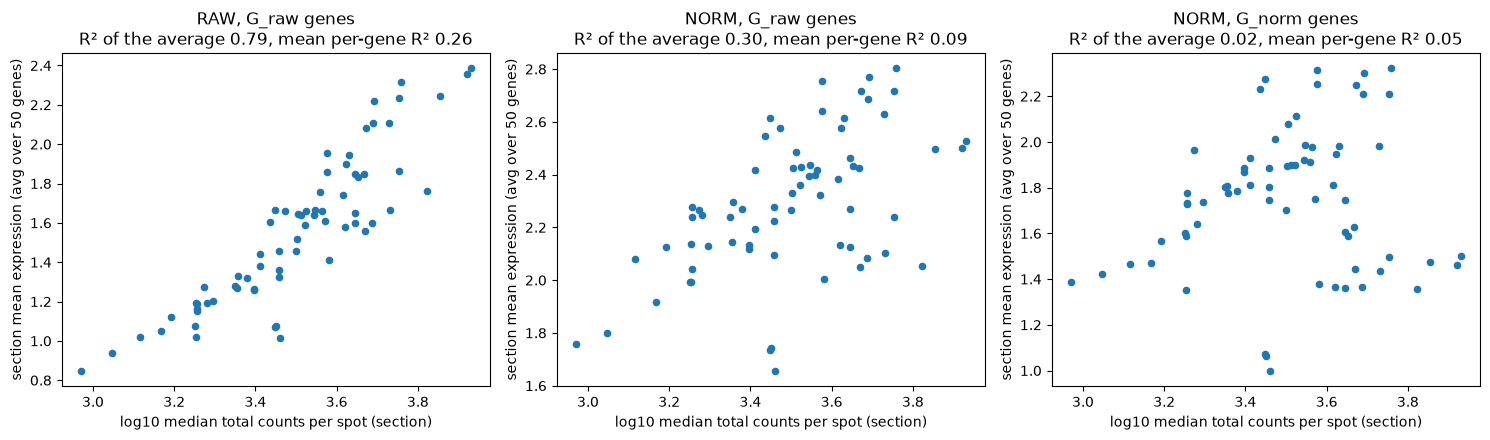

In [10]:
all_spots = np.arange(len(spots))
depth_genes = {"G_raw": choose_genes(Y, all_spots), "G_norm": choose_genes(Y_norm, all_spots)}
section_median_depth = np.array([np.median(total_counts[section_number == s]) for s in range(len(section_ids))])
log_depth = np.log10(section_median_depth)
print(f"Median total counts per spot, by section: {section_median_depth.min():.1f} to {section_median_depth.max():.1f}")


def section_means(Y_target, gene_index):
    y = Y_target[:, gene_index].toarray()
    return np.array([y[section_number == s].mean(axis=0) for s in range(len(section_ids))])


def r_squared(x, y):
    return np.corrcoef(x, y)[0, 1] ** 2


depth_checks = {
    "RAW, G_raw genes": section_means(Y, depth_genes["G_raw"]),
    "NORM, G_raw genes": section_means(Y_norm, depth_genes["G_raw"]),
    "NORM, G_norm genes": section_means(Y_norm, depth_genes["G_norm"]),
}
depth_rows = []
for name, means in depth_checks.items():
    gene_r2 = np.array([r_squared(log_depth, means[:, g]) for g in range(means.shape[1])])
    depth_rows.append({
        "target_and_genes": name,
        "mean_R2_over_genes": gene_r2.mean(),
        "median_R2_over_genes": np.median(gene_r2),
        "genes_with_R2_over_0.5": int(np.sum(gene_r2 > 0.5)),
        "R2_of_50_gene_average": r_squared(log_depth, means.mean(axis=1)),
    })
depth_r2 = pd.DataFrame(depth_rows)
print(depth_r2.round(3).to_string(index=False))

depth_by_section = pd.DataFrame({
    "section": section_ids,
    "patient": section_patient,
    "spots": section_size,
    "median_total_counts": section_median_depth,
    "mean_total_counts": [total_counts[section_number == s].mean() for s in range(len(section_ids))],
    "min_total_counts": [total_counts[section_number == s].min() for s in range(len(section_ids))],
    "zero_total_spots": [int(zero_total[section_number == s].sum()) for s in range(len(section_ids))],
    "raw_mean_G_raw": depth_checks["RAW, G_raw genes"].mean(axis=1),
    "norm_mean_G_raw": depth_checks["NORM, G_raw genes"].mean(axis=1),
    "norm_mean_G_norm": depth_checks["NORM, G_norm genes"].mean(axis=1),
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, means), (_, row) in zip(axes, depth_checks.items(), depth_r2.iterrows()):
    ax.scatter(log_depth, means.mean(axis=1), s=20, color="tab:blue")
    ax.set_xlabel("log10 median total counts per spot (section)")
    ax.set_ylabel("section mean expression (avg over 50 genes)")
    ax.set_title(f"{name}\nR² of the average {row['R2_of_50_gene_average']:.2f}, "
                 f"mean per-gene R² {row['mean_R2_over_genes']:.2f}")
plt.tight_layout()
save_figure("2_depth_diagnostic.png")
plt.show()

## Step 8. PCA inputs for every fold (as in MLP_JK_03)

On the fold's **training spots only**, three StandardScaler + PCA 256 transformations: `center` (the spot's own embedding), `mean_3x3` and `mean_5x5` (the averaged embeddings). They don't depend on the target, so all three runs share them.

- D = `center` + `mean_3x3` (512 numbers); E = `center` + `mean_5x5` (512 numbers).
- Ridge uses `center`, which is exactly Notebook 5's "ridge raw" input (StandardScaler + PCA 256 of the raw embeddings, fit on training spots).

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_3x3 = neighbor_mean(X_raw, neighborhoods["3x3"])
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
print(f"Averages done ({(time.time() - start_time) / 60:.1f} min)")

fold_inputs = []
for fold in range(N_FOLDS):
    train_index = fold_train_index[fold]
    fold_inputs.append({
        "center": pca_256(X_raw, train_index),
        "mean_3x3": pca_256(X_mean_3x3, train_index),
        "mean_5x5": pca_256(X_mean_5x5, train_index),
    })
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

del X_raw, X_mean_3x3, X_mean_5x5

Averages done (0.0 min)


fold 0: PCA inputs done (0.4 min)


fold 1: PCA inputs done (0.8 min)


fold 2: PCA inputs done (1.2 min)


fold 3: PCA inputs done (1.6 min)


## Step 9. Ridge, the MLP, and shrinkage (copied from Notebook 5 and MLP_JK_03)

**Ridge:** one alpha per gene, chosen by 3-fold patient-grouped cross-validation inside the training patients (`choose_alpha_per_gene`), then fit on all training spots.

**The MLP:** input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes). `train_mlp` uses Adam (weight decay 1e-3) and MSE loss on genes standardized with the training mean and SD, in mini-batches of 256. With validation spots it keeps the best validation epoch and stops after `PATIENCE` epochs without improvement; without them it trains for a fixed number of epochs. `shrink` = `train_mean + k × (prediction − train_mean)`.

In [12]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred

In [13]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 10. One run in one fold, start to finish

Everything that learns from data uses the fold's **training patients only**, and the run's own target:

| Step | Uses |
|---|---|
| Genes | the run's gene set for this fold (Step 6) |
| Gene means and SDs, ridge alphas | training spots |
| For each of the 4 validation groups | D's and E's MLP trained on the fit patients, early stopping on the validation patients |
| `k` | lowest validation NRMSE averaged over the 4 groups, separately for D and E |
| Epochs | median best epoch over the 4 groups |
| Final models | D and E on **all** training patients, 3 seeds each, predictions averaged |
| Test patients | used once, for scoring. The oracle O also uses the true test slide means, and is labeled as such |

The test spots' expression is `NaN` in every array the training reads, so any accidental use would show up right away.

In [14]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_fold(run, fold):
    Y_target = Y_targets[RUNS[run]["target"]]
    gene_index = fold_genes[RUNS[run]["gene_set"]][fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y_target[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_test = Y_target[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)
    center = fold_inputs[fold]["center"]

    def as_result(prediction, alpha=no_alpha):
        return {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                "y_pred": prediction, "alpha": alpha}

    test_results = {"mean": as_result(np.tile(train_mean, (len(test_index), 1)))}
    seed_results = {}

    alpha_per_gene = choose_alpha_per_gene(center[train_index], y_fold[train_index], patient_array[train_index])
    ridge_prediction = fit_and_predict(center[train_index], y_fold[train_index], center[test_index], alpha_per_gene)
    test_results["ridge"] = as_result(ridge_prediction, alpha_per_gene)

    val_rows = []
    chosen_rows = []
    for setup, neighbor_input in MLP_SETUPS.items():
        P_device = to_device(np.concatenate([center, fold_inputs[fold][neighbor_input]], axis=1))

        for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
            fit_mean = y_fold[fit_rows].mean(axis=0)
            val_result = {
                "fold": fold,
                "test_index": val_index,
                "genes": genes,
                "y_test": y_fold[val_index],
                "y_mean": np.tile(fit_mean, (len(val_index), 1)),
                "alpha": no_alpha,
            }
            mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

            trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
            val_pred = predict(trained, P_device, val_index)
            for k in SHRINK_FACTORS:
                val_result["y_pred"] = shrink(val_pred, fit_mean, k)
                scores, _ = score_model("MLP", [val_result], "y_pred")
                val_rows.append({
                    "run": run, "setup": setup, "fold": fold, "val_group": group, "k": k,
                    "val_PCC": scores["PCC"].mean(),
                    "val_NRMSE": scores["NRMSE"].mean(),
                    "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                    "best_epoch": trained["best_epoch"],
                })

        val_table = pd.DataFrame(val_rows)
        by_k = val_table[val_table["setup"] == setup].groupby("k").agg(
            val_PCC=("val_PCC", "mean"),
            val_NRMSE=("val_NRMSE", "mean"),
            val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
            epochs=("best_epoch", "median"),
        ).reset_index()
        chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
        chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
        chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
        chosen.update({"run": run, "setup": setup, "fold": fold})
        chosen_rows.append(chosen)

        seed_predictions = []
        for seed_number in range(N_FINAL_SEEDS):
            final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number)
            seed_predictions.append(predict(final, P_device, test_index))
        del P_device

        test_results[setup] = as_result(shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]))
        seed_results[setup] = [as_result(shrink(p, train_mean, chosen["k"])) for p in seed_predictions]

    test_results["O"] = as_result(replace_levels(test_results["D"]["y_pred"], test_index, y_test))
    seed_results["O"] = [as_result(replace_levels(r["y_pred"], test_index, y_test)) for r in seed_results["D"]]
    return test_results, seed_results, pd.DataFrame(val_rows), chosen_rows


results = {run: {model: [] for model in MODEL_NAMES} for run in RUNS}
seed_results = {run: {setup: [[] for _ in range(N_FINAL_SEEDS)] for setup in ["D", "E", "O"]} for run in RUNS}
val_tables = []
chosen_rows = []


def run_all_folds(run):
    start_time = time.time()
    for fold in range(N_FOLDS):
        fold_results, fold_seed_results, val_table, chosen = run_fold(run, fold)
        for model in MODEL_NAMES:
            results[run][model].append(fold_results[model])
        for setup, seed_list in fold_seed_results.items():
            for seed_number, seed_result in enumerate(seed_list):
                seed_results[run][setup][seed_number].append(seed_result)
        val_tables.append(val_table)
        chosen_rows.extend(chosen)
        ks = ", ".join(f"{c['setup']} k = {c['k']}" for c in chosen)
        print(f"{RUNS[run]['label']}, fold {fold} done: {ks}  ({(time.time() - start_time) / 60:.1f} min)", flush=True)
        if device.type == "mps":
            torch.mps.empty_cache()

## Step 11. Run 1 (RAW, G_raw), and check it against Notebook 5 and MLP_JK_03

Run 1 is exactly the old setup, so:
- ridge must reproduce Notebook 5's "ridge raw" (pooled PCC and NRMSE within 0.001);
- D and E must reproduce MLP_JK_03's D and E (pooled PCC within 0.01, test MSE within 0.005), on the same genes.

If any check fails, the notebook stops here.

In [15]:
run_all_folds("raw_Graw")

ridge_pooled, _ = score_model("ridge raw", results["raw_Graw"]["ridge"], "y_pred")
notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]
print(f"\nridge raw, this notebook: pooled PCC {ridge_pooled['PCC'].mean():.4f}, NRMSE {ridge_pooled['NRMSE'].mean():.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")
assert abs(ridge_pooled["PCC"].mean() - notebook_5_pcc) < RIDGE_TOLERANCE, "Ridge doesn't reproduce Notebook 5. Stop."
assert abs(ridge_pooled["NRMSE"].mean() - notebook_5_nrmse) < RIDGE_TOLERANCE, "Ridge doesn't reproduce Notebook 5. Stop."

check_pooled = pd.read_csv(os.path.join(CHECK_DIR, "pooled_gene_scores.csv"))
for setup in MLP_SETUPS:
    saved = check_pooled[check_pooled["model"] == MODEL_NAMES[setup]]
    for fold in range(N_FOLDS):
        assert set(saved.loc[saved["fold"] == fold, "gene"]) == set(all_genes[fold_genes["G_raw"][fold]]), \
            f"MLP_JK_03 {setup}, fold {fold}: genes differ"
    saved_mse = (saved["NRMSE"] * saved["test_SD"]) ** 2
    ours = [error_parts(r) for r in results["raw_Graw"][setup]]
    our_mse = np.sum([mse * n for mse, _, _, n in ours]) / np.sum([n for _, _, _, n in ours])
    our_pooled, _ = score_model(setup, results["raw_Graw"][setup], "y_pred")
    print(f"{MODEL_NAMES[setup]}: this notebook MSE {our_mse:.4f}, PCC {our_pooled['PCC'].mean():.4f} | "
          f"MLP_JK_03 MSE {saved_mse.mean():.4f}, PCC {saved['PCC'].mean():.4f}")
    assert abs(our_pooled["PCC"].mean() - saved["PCC"].mean()) <= CHECK_PCC_TOLERANCE, f"{setup}'s PCC is far from MLP_JK_03. Stop."
    assert abs(our_mse - saved_mse.mean()) <= CHECK_MSE_TOLERANCE, f"{setup}'s MSE is far from MLP_JK_03. Stop."
print("Run 1 reproduces Notebook 5 and MLP_JK_03.")

RAW, G_raw, fold 0 done: D k = 0.4, E k = 0.4  (0.5 min)


RAW, G_raw, fold 1 done: D k = 0.4, E k = 0.4  (1.1 min)


RAW, G_raw, fold 2 done: D k = 0.4, E k = 0.4  (1.6 min)


RAW, G_raw, fold 3 done: D k = 0.4, E k = 0.4  (2.1 min)



ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0918
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917


D 3x3 average: this notebook MSE 0.9584, PCC 0.2064 | MLP_JK_03 MSE 0.9584, PCC 0.2064


E 5x5 average: this notebook MSE 0.9589, PCC 0.1997 | MLP_JK_03 MSE 0.9589, PCC 0.1997
Run 1 reproduces Notebook 5 and MLP_JK_03.


## Step 12. Runs 2 and 3 (NORM)

In [16]:
run_all_folds("norm_Graw")
run_all_folds("norm_Gnorm")

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)

NORM, G_raw, fold 0 done: D k = 0.4, E k = 0.4  (0.6 min)


NORM, G_raw, fold 1 done: D k = 0.4, E k = 0.4  (1.3 min)


NORM, G_raw, fold 2 done: D k = 0.2, E k = 0.2  (1.9 min)


NORM, G_raw, fold 3 done: D k = 0.2, E k = 0.4  (2.5 min)


NORM, G_norm, fold 0 done: D k = 0.4, E k = 0.4  (0.9 min)


NORM, G_norm, fold 1 done: D k = 0.4, E k = 0.4  (1.5 min)


NORM, G_norm, fold 2 done: D k = 0.4, E k = 0.4  (2.2 min)


NORM, G_norm, fold 3 done: D k = 0.4, E k = 0.4  (2.8 min)


## Step 13. Results

**Chosen `k` and epochs**, per run, setup and fold (chosen on validation patients only). `passes` = validation NRMSE no worse than the mean predictor's.

In [17]:
pd.set_option("display.width", 250)
columns = ["run", "setup", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings[columns].round(4).to_string(index=False))

       run setup  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
  raw_Graw     D     0 0.4            10   0.2518     1.1087                    1.1430    True
  raw_Graw     E     0 0.4             8   0.2803     1.0994                    1.1430    True
  raw_Graw     D     1 0.4            10   0.1669     1.1137                    1.1307    True
  raw_Graw     E     1 0.4            10   0.1757     1.1128                    1.1307    True
  raw_Graw     D     2 0.4             9   0.1855     1.0681                    1.0955    True
  raw_Graw     E     2 0.4            12   0.2052     1.0659                    1.0955    True
  raw_Graw     D     3 0.4            10   0.2261     1.0647                    1.0824    True
  raw_Graw     E     3 0.4            12   0.2412     1.0577                    1.0824    True
 norm_Graw     D     0 0.4            16   0.1549     1.1153                    1.1315    True
 norm_Graw     E     0 0.4            14   0.1729 

**Scores per fold, and overall.** For every run and model, per fold: test MSE, MSE ratio (÷ the run's own mean predictor), pooled PCC, NRMSE, within-patient PCC, level and pattern error and the level share. Overall:
- PCC, NRMSE and within-patient PCC are averaged over all genes (and patients), as in earlier notebooks.
- MSE, level and pattern error are averaged over all scored genes.
- MSE ratio and level share are computed from those averages.

**Seed spread:** each of the 3 final seeds is scored on its own. A difference smaller than the range across seeds could just be luck.

In [18]:
def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "fold": fold, "MSE": mse, "level_error": level_error, "pattern_error": pattern_error,
            "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "genes_scored": n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within


summary_rows = []
fold_tables = []
pooled_tables = []
within_tables = []
for run, run_info in RUNS.items():
    mean_folds, mean_overall, _, _ = score_results(results[run]["mean"], "mean predictor")
    for model, model_name in MODEL_NAMES.items():
        folds, overall, pooled_part, within_part = score_results(results[run][model], model_name)
        folds["MSE_ratio"] = folds["MSE"] / mean_folds["MSE"]
        folds["level_share"] = folds["level_error"] / folds["MSE"]
        row = {"run": run, "target": run_info["target"], "gene_set": run_info["gene_set"], "model": model_name}
        row.update(overall)
        row["mean_predictor_MSE"] = mean_overall["test_MSE"]
        row["MSE_ratio"] = overall["test_MSE"] / mean_overall["test_MSE"]
        row["mean_predictor_NRMSE"] = mean_overall["NRMSE"]
        row["mean_predictor_level_share"] = mean_overall["level_share"]

        if model in MLP_SETUPS:
            c = chosen_settings[(chosen_settings["run"] == run) & (chosen_settings["setup"] == model)].sort_values("fold")
            row["val_PCC"] = c["val_PCC"].mean()
            row["val_NRMSE"] = c["val_NRMSE"].mean()
            row["val_mean_predictor_NRMSE"] = c["val_mean_predictor_NRMSE"].mean()
            row["chosen_k"] = "/".join(str(k) for k in c["k"])
        if model == "O":
            row["chosen_k"] = "same as D"
        if model in seed_results[run]:
            seed_overall = [score_results(seed_results[run][model][s], "seed")[1] for s in range(N_FINAL_SEEDS)]
            for metric in ["pooled_PCC", "within_PCC", "NRMSE", "level_share"]:
                values = [o[metric] for o in seed_overall]
                row[f"seed_range_{metric}"] = max(values) - min(values)
            ratios = [o["test_MSE"] / mean_overall["test_MSE"] for o in seed_overall]
            row["seed_range_MSE_ratio"] = max(ratios) - min(ratios)
        summary_rows.append(row)

        folds.insert(0, "model", model_name)
        folds.insert(0, "gene_set", run_info["gene_set"])
        folds.insert(0, "target", run_info["target"])
        folds.insert(0, "run", run)
        fold_tables.append(folds)
        pooled_part["run"] = run
        within_part["run"] = run
        pooled_tables.append(pooled_part)
        within_tables.append(within_part)

summary = pd.DataFrame(summary_rows)
fold_scores = pd.concat(fold_tables, ignore_index=True)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
assert np.allclose(summary["level_error"] + summary["pattern_error"], summary["test_MSE"]), "split doesn't add up"

summary_columns = ["target", "gene_set", "model", "test_MSE", "MSE_ratio", "pooled_PCC", "within_PCC", "NRMSE",
                   "val_PCC", "val_NRMSE", "chosen_k", "level_error", "pattern_error", "level_share"]
print(summary[summary_columns].round(4).to_string(index=False))
print("\nGenes scored (test SD >= 0.05), out of 200 per run:",
      summary.drop_duplicates("run").set_index("run")["genes_scored"].to_dict())
print("Level and pattern error add up to the test MSE in every fold, for every run and model.")

print("\nSeed spread (max - min over the 3 seeds):")
seed_columns = ["target", "gene_set", "model", "seed_range_MSE_ratio", "seed_range_pooled_PCC",
                "seed_range_within_PCC", "seed_range_NRMSE", "seed_range_level_share"]
print(summary[summary["model"].isin([MODEL_NAMES[m] for m in ["D", "E", "O"]])][seed_columns].round(4).to_string(index=False))

target gene_set                       model  test_MSE  MSE_ratio  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k  level_error  pattern_error  level_share
   raw    G_raw              mean predictor    1.0092     1.0000         NaN         NaN 1.0997      NaN        NaN             NaN       0.6074         0.4018       0.6019
   raw    G_raw                   ridge raw    0.9837     0.9747      0.1868      0.1515 1.0918      NaN        NaN             NaN       0.5704         0.4132       0.5799
   raw    G_raw               D 3x3 average    0.9584     0.9497      0.2064      0.1584 1.0709   0.2076     1.0888 0.4/0.4/0.4/0.4       0.5707         0.3878       0.5954
   raw    G_raw               E 5x5 average    0.9589     0.9501      0.1997      0.1694 1.0702   0.2256     1.0840 0.4/0.4/0.4/0.4       0.5725         0.3864       0.5970
   raw    G_raw O ORACLE (uses test labels)    0.3878     0.3842      0.6672      0.2557 0.7168      NaN        NaN       same as D    

**The mean predictor's level share** is independent of any model: it measures how much of the target's variation (around the training mean) is slide-to-slide. If normalization removes depth differences, this share should drop.

In [19]:
mean_rows = summary[summary["model"] == "mean predictor"]
print(mean_rows[["target", "gene_set", "test_MSE", "level_error", "pattern_error", "level_share"]].round(4).to_string(index=False))
print()
for column, title in [("MSE_ratio", "MSE ratio (model / mean predictor)"), ("PCC", "Pooled PCC"),
                      ("NRMSE", "NRMSE"), ("PCC_within", "Within-patient PCC"), ("level_share", "Level share")]:
    print(f"{title} per fold:")
    table = fold_scores.pivot_table(index=["model", "run"], columns="fold", values=column)
    order = [(MODEL_NAMES[m], run) for m in MODEL_NAMES for run in RUNS]
    print(table.reindex(order).round(4).to_string())
    print()

target gene_set  test_MSE  level_error  pattern_error  level_share
   raw    G_raw    1.0092       0.6074         0.4018       0.6019
  norm    G_raw    1.5546       0.9077         0.6469       0.5839
  norm   G_norm    1.7055       0.9808         0.7247       0.5751

MSE ratio (model / mean predictor) per fold:
fold                                         0       1       2       3
model                       run                                       
mean predictor              raw_Graw    1.0000  1.0000  1.0000  1.0000
                            norm_Graw   1.0000  1.0000  1.0000  1.0000
                            norm_Gnorm  1.0000  1.0000  1.0000  1.0000
ridge raw                   raw_Graw    1.0254  0.9170  1.0266  0.9368
                            norm_Graw   1.0224  0.9684  0.9997  0.9809
                            norm_Gnorm  1.0035  0.9565  0.9998  0.9747
D 3x3 average               raw_Graw    0.9727  0.9192  0.9620  0.9487
                            norm_Graw   0.9769 

## Step 14. NORM vs. RAW, and the verdict

**Comparisons:** for each model, run 2 − run 1 (same genes) and run 3 − run 1 (the new genes), per fold, on the metrics that are comparable across targets. `folds_NORM_better` counts the folds where NORM is better (lower NRMSE, MSE ratio and level share; higher PCC). `seed_spread` is the larger seed range of the two runs (0 for the mean predictor and ridge, which have no seeds). `real` = NORM better in at least 3 of 4 folds **and** the mean difference bigger than the seed spread.

**Verdict (decision rule):** the best-validation model of run 1 (RAW) is compared with the best-validation model of run 3 (NORM, G_norm). NORM is adopted if (a) its level share is lower, and the drop is real, and (b) its validation PCC is at least RAW's minus 0.005. The validation PCCs are on different targets and genes, so (b) is approximate.

In [20]:
METRICS = {"NRMSE": "lower", "MSE_ratio": "lower", "PCC": "higher", "PCC_within": "higher", "level_share": "lower"}
SEED_COLUMN = {"NRMSE": "seed_range_NRMSE", "MSE_ratio": "seed_range_MSE_ratio", "PCC": "seed_range_pooled_PCC",
               "PCC_within": "seed_range_within_PCC", "level_share": "seed_range_level_share"}


def fold_values(run, model_name, metric):
    rows = fold_scores[(fold_scores["run"] == run) & (fold_scores["model"] == model_name)].sort_values("fold")
    return rows[metric].to_numpy()


def seed_spread(run, model_name, metric):
    value = summary.loc[(summary["run"] == run) & (summary["model"] == model_name), SEED_COLUMN[metric]]
    return 0.0 if value.isna().all() else float(value.iloc[0])


comparison_rows = []
for new_run in ["norm_Graw", "norm_Gnorm"]:
    for model, model_name in MODEL_NAMES.items():
        for metric, better in METRICS.items():
            difference = fold_values(new_run, model_name, metric) - fold_values("raw_Graw", model_name, metric)
            if np.all(np.isnan(difference)):
                continue
            norm_better = (difference < 0) if better == "lower" else (difference > 0)
            spread = max(seed_spread(new_run, model_name, metric), seed_spread("raw_Graw", model_name, metric))
            mean_difference = np.nanmean(difference)
            right_direction = mean_difference < 0 if better == "lower" else mean_difference > 0
            comparison_rows.append({
                "comparison": f"{RUNS[new_run]['label']} - RAW, G_raw",
                "model": model_name,
                "metric": metric,
                "better_is": better,
                "difference": mean_difference,
                "fold_differences": " ".join(f"{d:+.4f}" for d in difference),
                "folds_NORM_better": int(norm_better.sum()),
                "seed_spread": spread,
                "real": bool(right_direction and norm_better.sum() >= 3 and abs(mean_difference) > spread),
            })
comparisons = pd.DataFrame(comparison_rows)
print(comparisons.round(4).to_string(index=False))

               comparison                       model      metric better_is  difference                fold_differences  folds_NORM_better  seed_spread  real
 NORM, G_raw - RAW, G_raw              mean predictor       NRMSE     lower      0.0072 +0.0041 +0.0107 +0.0228 -0.0086                  1       0.0000 False
 NORM, G_raw - RAW, G_raw              mean predictor   MSE_ratio     lower      0.0000 +0.0000 +0.0000 +0.0000 +0.0000                  0       0.0000 False
 NORM, G_raw - RAW, G_raw              mean predictor level_share     lower     -0.0160 -0.0090 -0.0322 +0.0266 -0.0496                  3       0.0000  True
 NORM, G_raw - RAW, G_raw                   ridge raw       NRMSE     lower      0.0187 +0.0045 +0.0466 +0.0029 +0.0208                  0       0.0000 False
 NORM, G_raw - RAW, G_raw                   ridge raw   MSE_ratio     lower      0.0164 -0.0030 +0.0514 -0.0269 +0.0440                  2       0.0000 False
 NORM, G_raw - RAW, G_raw                   ridge ra

In [21]:
def best_validation_row(run):
    rows = summary[(summary["run"] == run) & summary["model"].isin([MODEL_NAMES[m] for m in MLP_SETUPS])]
    return rows.loc[rows["val_PCC"].idxmax()]


raw_best = best_validation_row("raw_Graw")
norm_best = best_validation_row("norm_Gnorm")
share_drop = fold_values("norm_Gnorm", norm_best["model"], "level_share") - fold_values("raw_Graw", raw_best["model"], "level_share")
share_spread = max(seed_spread("norm_Gnorm", norm_best["model"], "level_share"),
                   seed_spread("raw_Graw", raw_best["model"], "level_share"))
lower_share = share_drop.mean() < 0 and (share_drop < 0).sum() >= 3 and abs(share_drop.mean()) > share_spread
keeps_val_pcc = norm_best["val_PCC"] >= raw_best["val_PCC"] - VAL_PCC_TOLERANCE
adopt = lower_share and keeps_val_pcc

mean_share = summary[summary["model"] == "mean predictor"].set_index("run")["level_share"]
verdict_lines = [
    "Mean predictor's level share (how much of the target's variation is slide to slide, no model):",
    f"  RAW, G_raw {mean_share['raw_Graw']:.1%} | NORM, G_raw {mean_share['norm_Graw']:.1%} | "
    f"NORM, G_norm {mean_share['norm_Gnorm']:.1%}",
    "",
    f"Best-validation model, RAW (G_raw):   {raw_best['model']}, validation PCC {raw_best['val_PCC']:.4f}, "
    f"level share {raw_best['level_share']:.1%}",
    f"Best-validation model, NORM (G_norm): {norm_best['model']}, validation PCC {norm_best['val_PCC']:.4f}, "
    f"level share {norm_best['level_share']:.1%}",
    f"Level share change per fold: {' '.join(f'{d:+.3f}' for d in share_drop)} "
    f"(mean {share_drop.mean():+.3f}, lower in {(share_drop < 0).sum()}/4 folds, seed spread {share_spread:.3f})",
    f"(a) Level share lower, and the drop is real: {'yes' if lower_share else 'no'}",
    f"(b) Validation PCC not lower by more than {VAL_PCC_TOLERANCE}: {'yes' if keeps_val_pcc else 'no'} "
    f"({norm_best['val_PCC'] - raw_best['val_PCC']:+.4f})",
    "",
]
if adopt:
    verdict_lines.append("VERDICT: adopt NORM. Normalizing counts lowers the slide-level share of the error "
                         "without costing validation PCC.")
else:
    reasons = []
    if not lower_share:
        reasons.append("the level share does not drop clearly")
    if not keeps_val_pcc:
        reasons.append("validation PCC drops")
    verdict_lines.append("VERDICT: keep RAW for now, because " + " and ".join(reasons) + ".")
verdict = "\n".join(verdict_lines)
print(verdict)

Mean predictor's level share (how much of the target's variation is slide to slide, no model):
  RAW, G_raw 60.2% | NORM, G_raw 58.4% | NORM, G_norm 57.5%

Best-validation model, RAW (G_raw):   E 5x5 average, validation PCC 0.2256, level share 59.7%
Best-validation model, NORM (G_norm): E 5x5 average, validation PCC 0.1877, level share 56.3%
Level share change per fold: -0.021 -0.025 -0.025 -0.058 (mean -0.032, lower in 4/4 folds, seed spread 0.001)
(a) Level share lower, and the drop is real: yes
(b) Validation PCC not lower by more than 0.005: no (-0.0379)

VERDICT: keep RAW for now, because validation PCC drops.


## Step 15. Plots

**Figure 1: the error split, RAW vs. NORM.** Each bar is one model in one run, as a fraction of that run's **mean predictor MSE** (so the scales are comparable; the mean predictor is 1). Bottom (red) = level error, top (blue) = pattern error; the number is the level share. The oracle is left out (its level error is 0 by construction).

**Figure 3: pooled PCC and NRMSE per model, RAW vs. NORM.** Bars = average over folds, dots = the 4 folds.

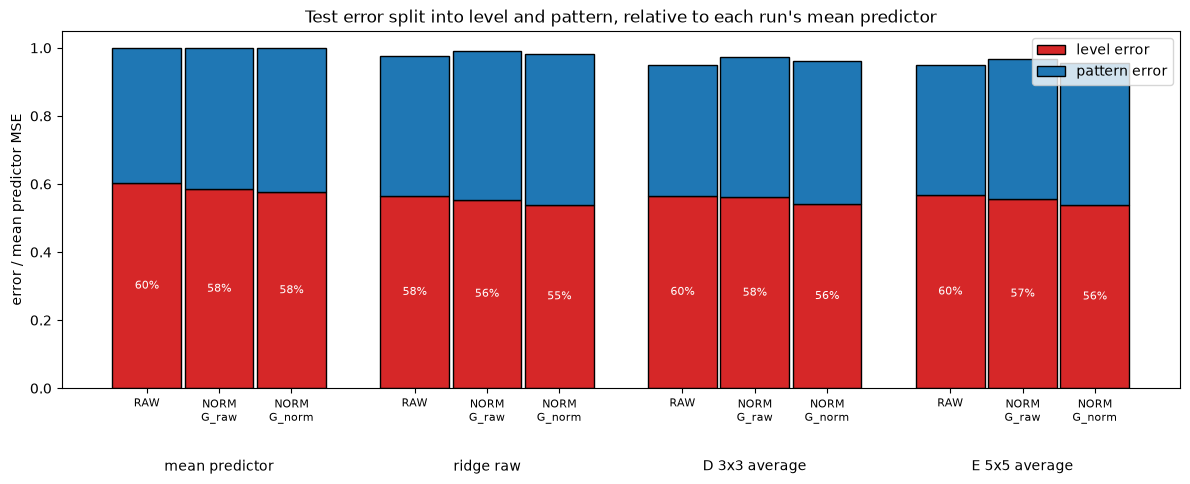

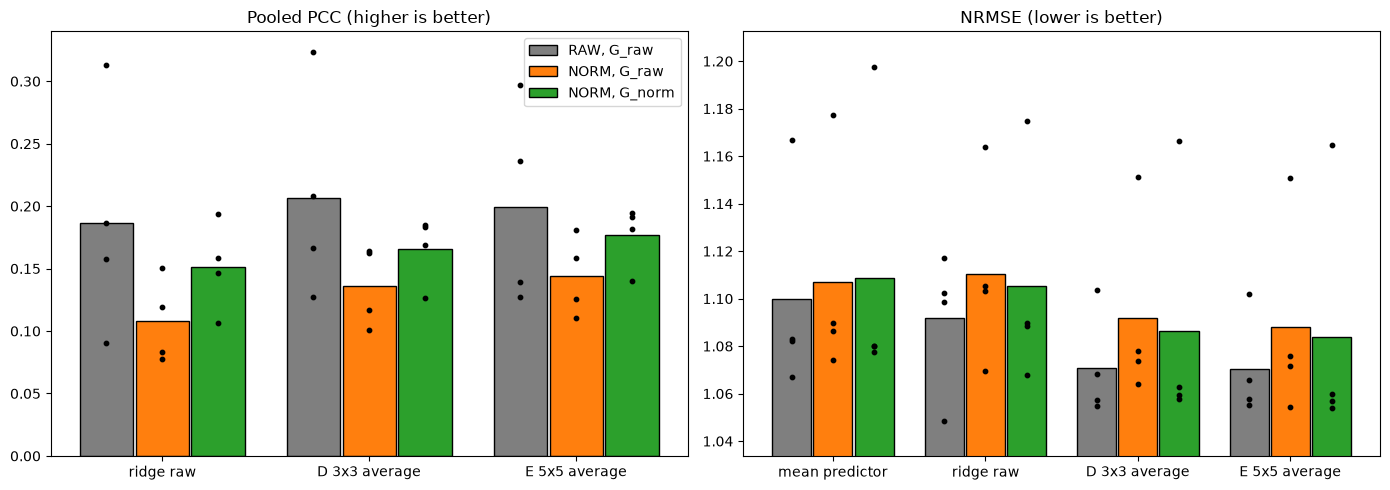

In [22]:
run_colors = {"raw_Graw": "tab:gray", "norm_Graw": "tab:orange", "norm_Gnorm": "tab:green"}
run_short = {"raw_Graw": "RAW", "norm_Graw": "NORM\nG_raw", "norm_Gnorm": "NORM\nG_norm"}
plot_models = ["mean", "ridge", "D", "E"]
width = 0.27

fig, ax = plt.subplots(figsize=(12, 5))
tick_positions = []
tick_labels = []
for m, model in enumerate(plot_models):
    for r, run in enumerate(RUNS):
        row = summary[(summary["run"] == run) & (summary["model"] == MODEL_NAMES[model])].iloc[0]
        x = m + (r - 1) * width
        level = row["level_error"] / row["mean_predictor_MSE"]
        pattern = row["pattern_error"] / row["mean_predictor_MSE"]
        ax.bar(x, level, width * 0.95, color="tab:red", edgecolor="black", label="level error" if m + r == 0 else None)
        ax.bar(x, pattern, width * 0.95, bottom=level, color="tab:blue", edgecolor="black",
               label="pattern error" if m + r == 0 else None)
        ax.text(x, level / 2, f"{row['level_share']:.0%}", ha="center", va="center", color="white", fontsize=8)
        tick_positions.append(x)
        tick_labels.append(run_short[run])
    ax.text(m, -0.2, MODEL_NAMES[model], ha="center", va="top", fontsize=10, transform=ax.get_xaxis_transform())
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=8)
ax.set_ylabel("error / mean predictor MSE")
ax.set_title("Test error split into level and pattern, relative to each run's mean predictor")
ax.legend(loc="upper right")
plt.tight_layout()
save_figure("1_error_split.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, title, models in [(axes[0], "PCC", "Pooled PCC (higher is better)", ["ridge", "D", "E"]),
                                  (axes[1], "NRMSE", "NRMSE (lower is better)", ["mean", "ridge", "D", "E"])]:
    for m, model in enumerate(models):
        for r, run in enumerate(RUNS):
            values = fold_values(run, MODEL_NAMES[model], column)
            x = m + (r - 1) * width
            ax.bar(x, values.mean(), width * 0.95, color=run_colors[run], edgecolor="black",
                   label=RUNS[run]["label"] if m == 0 else None)
            ax.scatter(np.full(len(values), x), values, color="black", s=10, zorder=3)
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels([MODEL_NAMES[m] for m in models])
    ax.set_title(title)
low = fold_scores.loc[fold_scores["model"].isin([MODEL_NAMES[m] for m in plot_models]), "NRMSE"].min()
high = fold_scores.loc[fold_scores["model"].isin([MODEL_NAMES[m] for m in plot_models]), "NRMSE"].max()
axes[1].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
axes[0].legend()
plt.tight_layout()
save_figure("3_pcc_and_nrmse.png")
plt.show()

## Step 16. Best check (report only)

The usual rule: a model would qualify to replace MLP_JK_Best if its **validation PCC is higher** than the current best's and its validation NRMSE is no worse than the mean predictor's. Test scores are not used, and the oracle is never considered. For NORM runs the validation PCC is measured on NORM values, so it isn't exactly the same quantity as the current best's.

**This notebook does not change MLP_JK_Best.** It only writes `best_check.csv`.

In [23]:
best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv"))
best_row = best_summary[best_summary["val_PCC"].notna() & ~best_summary["model"].str.contains("logged")].iloc[0]
best_val_PCC = best_row["val_PCC"]
print(f"Current MLP_JK_Best ({best_row['model']}): validation PCC {best_val_PCC:.4f}\n")

best_rows = []
for run, run_info in RUNS.items():
    for setup in MLP_SETUPS:
        row = summary[(summary["run"] == run) & (summary["model"] == MODEL_NAMES[setup])].iloc[0]
        passes = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
        note = ""
        if run == "raw_Graw" and setup == "E":
            note = "the current Best's own setup (reproduction)"
        elif run_info["target"] == "norm":
            note = "validation PCC on NORM values"
        best_rows.append({
            "target": run_info["target"], "gene_set": run_info["gene_set"], "model": MODEL_NAMES[setup],
            "val_PCC": row["val_PCC"], "val_NRMSE": row["val_NRMSE"],
            "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"],
            "passes_NRMSE_rule": passes, "current_best_val_PCC": best_val_PCC,
            "would_beat_best": passes and row["val_PCC"] > best_val_PCC, "note": note,
        })
best_check = pd.DataFrame(best_rows)
print(best_check.round(4).to_string(index=False))
if best_check["would_beat_best"].any():
    print("\nAt least one model passes the rule. MLP_JK_Best is NOT changed here; this is for review.")
else:
    print("\nNo model passes the rule. MLP_JK_Best is unchanged.")

Current MLP_JK_Best (E 5x5 average): validation PCC 0.2256

target gene_set         model  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  current_best_val_PCC  would_beat_best                                        note
   raw    G_raw D 3x3 average   0.2076     1.0888                    1.1129               True                0.2256            False                                            
   raw    G_raw E 5x5 average   0.2256     1.0840                    1.1129               True                0.2256            False the current Best's own setup (reproduction)
  norm    G_raw D 3x3 average   0.1335     1.0920                    1.1048               True                0.2256            False               validation PCC on NORM values
  norm    G_raw E 5x5 average   0.1520     1.0889                    1.1048               True                0.2256            False               validation PCC on NORM values
  norm   G_norm D 3x3 average   0.1739     1.0821 

## Step 17. Save results and add them to the log

`all_results.csv` gets a new `target` column (`raw` / `norm`); every earlier row used the RAW target, so they are filled with `raw`. This notebook adds one row per run and model (the condition names the gene set; the oracle is clearly named as one). If this notebook is run again, its old rows are replaced instead of duplicated.

In [24]:
summary_out = summary[summary_columns + ["mean_predictor_MSE", "mean_predictor_NRMSE", "mean_predictor_level_share",
                                         "val_mean_predictor_NRMSE", "genes_scored"]
                      + [c for c in summary.columns if c.startswith("seed_range")]]
summary_out.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
gene_overlap.to_csv(os.path.join(OUT_DIR, "gene_overlap.csv"), index=False)
depth_by_section.to_csv(os.path.join(OUT_DIR, "depth_by_section.csv"), index=False)
depth_r2.to_csv(os.path.join(OUT_DIR, "depth_r2.csv"), index=False)
comparisons.to_csv(os.path.join(OUT_DIR, "comparisons.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
with open(os.path.join(OUT_DIR, "verdict.txt"), "w") as f:
    f.write(verdict + "\n")

settings = {
    "notebook": NOTEBOOK_NAME,
    "runs": RUNS,
    "model_names": MODEL_NAMES,
    "target_sum": TARGET_SUM,
    "zero_total_spots": int(zero_total.sum()),
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "val_pcc_tolerance": VAL_PCC_TOLERANCE,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": f"{row['model']} | {row['gene_set']} genes",
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": row["mean_predictor_NRMSE"],
            "val_PCC": row.get("val_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
            "target": row["target"],
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        if "target" not in old_rows.columns:
            old_rows["target"] = "raw"
        old_rows["target"] = old_rows["target"].fillna("raw")
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.tail(15).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                                  condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date target
MLP_JK_07               mean predictor | G_raw genes         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-18    raw
MLP_JK_07                    ridge raw | G_raw genes      0.1868              0.1515 1.0918                1.0997      NaN        NaN 2026-11-18    raw
MLP_JK_07                D 3x3 average | G_raw genes      0.2064              0.1584 1.0709                1.0997   0.2076     1.0888 2026-11-18    raw
MLP_JK_07                E 5x5 average | G_raw genes      0.1997              0.1694 1.0702                1.0997   0.2256     1.0840 2026-11-18    raw
MLP_JK_07  O ORACLE (uses test labels) | G_raw genes      0.6672              0.2557 0.7168                1.0997      NaN        NaN 2026-11-18    raw
MLP_JK_07               mean predictor | G_raw genes         NaN                 NaN 1.1

## Summary in plain words: is the slide-level error just sequencing depth?

**Checks first**
- Counts come back cleanly: `expm1` of the stored values is within 0.0003 of a whole number, and `log1p` of the recovered counts matches the stored values (2e-7).
- **Totals** use the **11,787 genes in `genes.txt`** (the genes in our expression files), **not the 18,126 genes in the raw h5ad files**. Note: 299 of those 11,787 entries are `__ambiguous[...]` read bins (reads that could belong to two genes), not real genes; they hold 2.8% of all counts and are included in the totals as specified. One of them is even among the top 50 "genes" of RAW in folds 1 and 2 (also in earlier notebooks).
- One spot has total = 0 (SPA64, barcode 018x018); its NORM values are all 0, like its RAW values.
- Run 1 reproduced Notebook 5's ridge (pooled PCC 0.1868) and MLP_JK_03's D (MSE 0.9584, PCC 0.2064) and E (MSE 0.9589, PCC 0.1997) exactly.
- Level + pattern error add up to the MSE in every fold, for every run and model. All 50 genes pass the test SD ≥ 0.05 filter in every run.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **MSE ratio** | Model MSE ÷ the same run's mean predictor MSE (MSE itself can't be compared across targets) | Below 1 = better than guessing the training average; lower is better |
| **Level share** | The fraction of the MSE that comes from each slide's **predicted mean** being off (slide-to-slide error) | Lower = less of the error is about whole slides being shifted |
| **NRMSE** | The error divided by the gene's spread in the test patients | Lower is better; below the mean predictor = better than guessing |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots | 0 = no relation, 1 = perfect |
| **Within-patient PCC** | The same correlation inside one patient at a time | Higher is better |
| **Validation PCC** | PCC on held-out *training* patients; the only score used for choosing | Higher is better |
| **R² (depth)** | How much of the slide-to-slide variation in a gene's level is explained by the slide's sequencing depth | 0 = none, 1 = all |

A difference is called **real** only if it holds in at least 3 of 4 folds **and** is bigger than the seed spread.

### Depth explains RAW slide levels, and NORM removes that

| | R² of the 50-gene average | Mean per-gene R² |
|---|---|---|
| RAW, G_raw genes | **0.79** | 0.26 |
| NORM, G_raw genes | 0.30 | 0.09 |
| NORM, G_norm genes | 0.02 | 0.05 |

In RAW, a slide's overall level is mostly its sequencing depth (Figure 2, left). Normalization removes almost all of that.

### But the slide-level error barely shrinks

| Run | Mean predictor level share | Best-validation model (E) level share | E: MSE ratio | E: NRMSE | E: pooled PCC | E: within-patient PCC | E: validation PCC |
|---|---|---|---|---|---|---|---|
| RAW, G_raw | 60.2% | 59.7% | 0.950 | 1.070 | 0.200 | 0.169 | **0.226** |
| NORM, G_raw | 58.4% | 57.4% | 0.967 | 1.088 | 0.144 | 0.104 | 0.152 |
| NORM, G_norm | 57.5% | 56.3% | 0.956 | 1.084 | 0.177 | 0.107 | 0.188 |

- **The target itself:** even with no model, normalization only lowers the slide-to-slide share of the variation from 60% to 58% (same genes) or 57.5% (new genes). So **depth is not why 60% of the error is slide level.** After removing depth, slides still differ in level just as much in relative terms; that is probably real differences in tissue makeup between slides and patients (and other batch effects), which the images also can't predict well.
- **The drop is real but small:** E's level share falls by 3.2 points with G_norm, in all 4 folds, far beyond the seed spread (0.001). The same holds for D, ridge and the mean predictor.
- **Accuracy gets worse, not better:** relative to its own mean predictor, every model does worse on NORM. MSE ratio and NRMSE are worse on average (G_raw: worse in 3–4 of 4 folds; G_norm: mixed, 2 of 4). Pooled PCC drops (E 0.200 → 0.177 with G_norm), and **within-patient PCC drops a lot in all 4 folds** (E 0.169 → 0.107).
- **Why the images lose signal:** in RAW, a spot's counts also reflect how much tissue/cells sit under it, which the images can see. Normalizing removes that "how much tissue" signal and leaves only the relative mix of genes, which is harder to read from the image.
- **New genes (G_norm) help NORM** compared with the old genes (E validation PCC 0.152 → 0.188), but not enough to catch up with RAW. The two gene sets share only 26–33 of 50 genes per fold.

### Verdict

The decision rule: adopt NORM if it lowers the level share (real) **without lowering validation PCC by more than 0.005**.
- (a) Level share lower and real: **yes** (59.7% → 56.3%, 4 of 4 folds).
- (b) Validation PCC kept: **no** (0.226 → 0.188, −0.038).

**Keep RAW for later experiments.** Normalization removes the depth effect from the target, but the slide-level share of the error barely changes, and the images predict the normalized target clearly worse.

**Best model:** no NORM model beats the current Best's validation PCC (0.226); RAW E is the Best itself. `best_check.csv` records this, and **MLP_JK_Best was not changed.**

**What this means for the 60% slide-level error:** it's not mainly sequencing depth. Most of it is slide-to-slide (and patient-to-patient) differences that remain after normalization, and the images don't predict them (as MLP_JK_06 already found).